In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split 
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

from sklearn import svm

## Загрузка данных

In [2]:
from sklearn.datasets import load_digits 
digits = load_digits()

print(digits['DESCR'])
print(digits.keys())

.. _digits_dataset:

Optical recognition of handwritten digits dataset
--------------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 1797
:Number of Attributes: 64
:Attribute Information: 8x8 image of integer pixels in the range 0..16.
:Missing Attribute Values: None
:Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)
:Date: July; 1998

This is a copy of the test set of the UCI ML hand-written digits datasets
https://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits

The data set contains images of hand-written digits: 10 classes where
each class refers to a digit.

Preprocessing programs made available by NIST were used to extract
normalized bitmaps of handwritten digits from a preprinted form. From a
total of 43 people, 30 contributed to the training set and different 13
to the test set. 32x32 bitmaps are divided into nonoverlapping blocks of
4x4 and the number of on pixels are counted in each block. This generates
an in

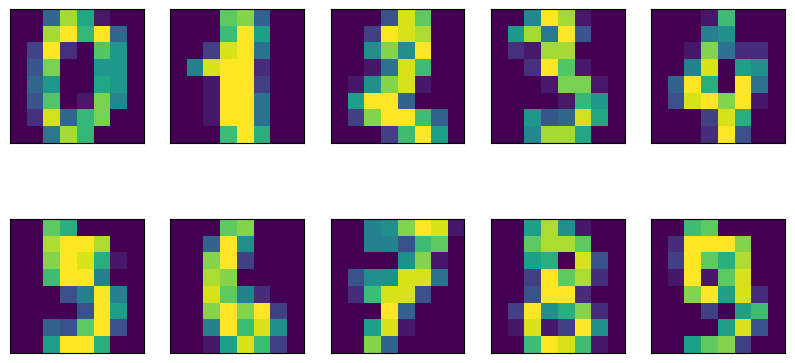

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5), subplot_kw={'xticks':(), 'yticks': ()})

for ax, img in zip(axes.ravel(), digits.images): 
    ax.imshow(img)

In [4]:
digits.target[:100]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 0, 1,
       2, 3, 4, 5, 6, 7, 8, 9, 0, 9, 5, 5, 6, 5, 0, 9, 8, 9, 8, 4, 1, 7,
       7, 3, 5, 1, 0, 0, 2, 2, 7, 8, 2, 0, 1, 2, 6, 3, 3, 7, 3, 3, 4, 6,
       6, 6, 4, 9, 1, 5, 0, 9, 5, 2, 8, 2, 0, 0, 1, 7, 6, 3, 2, 1, 7, 4,
       6, 3, 1, 3, 9, 1, 7, 6, 8, 4, 3, 1])

In [5]:
### Самостоятельно! Разложите картинки правильно по своим корзинкам!

In [6]:
# Картинка - матрица
digits.images[:2]

array([[[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
        [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
        [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
        [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
        [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
        [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
        [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
        [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]],

       [[ 0.,  0.,  0., 12., 13.,  5.,  0.,  0.],
        [ 0.,  0.,  0., 11., 16.,  9.,  0.,  0.],
        [ 0.,  0.,  3., 15., 16.,  6.,  0.,  0.],
        [ 0.,  7., 15., 16., 16.,  2.,  0.,  0.],
        [ 0.,  0.,  1., 16., 16.,  3.,  0.,  0.],
        [ 0.,  0.,  1., 16., 16.,  6.,  0.,  0.],
        [ 0.,  0.,  1., 16., 16.,  6.,  0.,  0.],
        [ 0.,  0.,  0., 11., 16., 10.,  0.,  0.]]])

In [7]:
# Данные в векторной форме
digits.data[:2]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
        15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
        12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
         0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
        10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.],
       [ 0.,  0.,  0., 12., 13.,  5.,  0.,  0.,  0.,  0.,  0., 11., 16.,
         9.,  0.,  0.,  0.,  0.,  3., 15., 16.,  6.,  0.,  0.,  0.,  7.,
        15., 16., 16.,  2.,  0.,  0.,  0.,  0.,  1., 16., 16.,  3.,  0.,
         0.,  0.,  0.,  1., 16., 16.,  6.,  0.,  0.,  0.,  0.,  1., 16.,
        16.,  6.,  0.,  0.,  0.,  0.,  0., 11., 16., 10.,  0.,  0.]])

## Делим данные

In [8]:
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target, random_state =42) 

## Элементарный контейнер

In [9]:
digit = make_pipeline( MinMaxScaler(), SVC(kernel='sigmoid') )
digit.fit(X_train, y_train)
y_predict = digit.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        43
           1       0.72      0.76      0.74        37
           2       0.94      0.89      0.92        38
           3       1.00      0.93      0.97        46
           4       0.93      0.95      0.94        55
           5       0.97      0.95      0.96        59
           6       0.96      0.98      0.97        45
           7       0.93      0.98      0.95        41
           8       0.81      0.79      0.80        38
           9       0.86      0.88      0.87        48

    accuracy                           0.91       450
   macro avg       0.91      0.91      0.91       450
weighted avg       0.91      0.91      0.91       450



In [10]:
digit = make_pipeline( MinMaxScaler(), SVC(kernel='rbf') )
digit.fit(X_train, y_train)
y_predict = digit.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        38
           3       1.00      0.98      0.99        46
           4       1.00      1.00      1.00        55
           5       0.98      1.00      0.99        59
           6       1.00      1.00      1.00        45
           7       0.98      0.98      0.98        41
           8       0.97      0.97      0.97        38
           9       0.96      0.96      0.96        48

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450



In [11]:
## Постройте свою модель

In [12]:

digit = make_pipeline( MinMaxScaler(), SVC(kernel='poly', degree = 5) )
digit.fit(X_train, y_train)
y_predict = digit.predict(X_test)

from sklearn.metrics import classification_report
print(digit.score(X_train, y_train))
print(classification_report(y_test, y_predict))

1.0
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        38
           3       0.98      0.96      0.97        46
           4       1.00      1.00      1.00        55
           5       0.98      1.00      0.99        59
           6       1.00      1.00      1.00        45
           7       0.98      0.98      0.98        41
           8       0.97      1.00      0.99        38
           9       0.98      0.96      0.97        48

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450



In [13]:
digit = make_pipeline( MinMaxScaler(), SVC(kernel='rbf', gamma = 'scale', C = 1.1) )
digit.fit(X_train, y_train)
y_predict = digit.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_predict))
print(digit.score(X_train, y_train))
digit.score(X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       1.00      1.00      1.00        38
           3       1.00      0.98      0.99        46
           4       1.00      1.00      1.00        55
           5       1.00      1.00      1.00        59
           6       1.00      1.00      1.00        45
           7       0.98      0.98      0.98        41
           8       0.97      0.97      0.97        38
           9       0.96      0.98      0.97        48

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450

0.9962880475129918


0.9911111111111112

## Вариант метода SVC - NuSVC

В отличие от классического SVC (где "гладкость" разделяющего зазора регулируется параметром `C`, значение которого сложно интуитивно подобрать), в Nu-SVC используется параметр `nu`:
- задается в диапазоне от $(0, 1]$
- значение `nu` работает одновременно для подбор верхней границы на долю ошибок классификации (на обучающей выборке) и на нижнею границу доли опорных векторов

Если параметр `nu = 0.1`, алгоритм постарается сделать так, чтобы опорных векторов было не менее 10% от общего числа обучающих объектов, а количество ошибок классификации (объектов по «неправильную» сторону разделяющей гиперплоскости или внутри зазора) не превышало примерно 10%

In [14]:
from sklearn.svm import NuSVC

digit = make_pipeline( MinMaxScaler(), NuSVC(kernel='rbf', gamma = 'scale', nu = 0.02) )
digit.fit(X_train, y_train)
y_predict = digit.predict(X_test)

from sklearn.metrics import classification_report
print(classification_report(y_test, y_predict))
print(digit.score(X_train, y_train))
digit.score(X_test, y_test)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        43
           1       1.00      1.00      1.00        37
           2       0.97      1.00      0.99        38
           3       1.00      0.96      0.98        46
           4       1.00      1.00      1.00        55
           5       0.98      1.00      0.99        59
           6       1.00      1.00      1.00        45
           7       0.98      0.98      0.98        41
           8       1.00      1.00      1.00        38
           9       0.98      0.98      0.98        48

    accuracy                           0.99       450
   macro avg       0.99      0.99      0.99       450
weighted avg       0.99      0.99      0.99       450

1.0


0.9911111111111112